# Implementação do FCM(Original) e Obtenção Empírica da Função Tempo

In [2]:
# Lista os arquivos da pasta atual
import os
print("Arquivos aqui:", os.listdir('.'))
# Lista os arquivos da pasta de cima (um nível acima)
print("Arquivos um nível acima:", os.listdir('..'))

Arquivos aqui: ['relatorio_fcm_original.ipynb', 'natural.jpeg', 'Rubens.jpg', 'img_output.png', 'lista_imagens']
Arquivos um nível acima: ['__pycache__', 'fcm_codigo_original', 'FCM_PURO_v3.py', 'Relatório_Credito2_EP', 'experimentador']


In [1]:
imagem_entrada = "natural.jpeg"          

--- INICIANDO PROCESSAMENTO DE BANCADA ---
Figura de Entrada: natural.jpeg
Clusters (K): 4


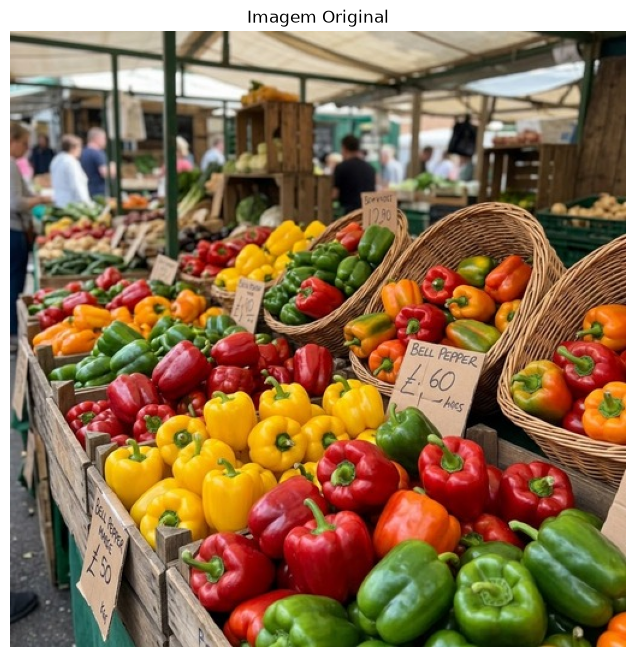

/tmp/ipykernel_869112/3127697586.py:15: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels_2d = list(img.getdata())


-> Convergiu na iteração 39!

[SUCESSO] Processamento finalizado com folga!
Tempo Total de Execução (Bancada): 60.5384 segundos


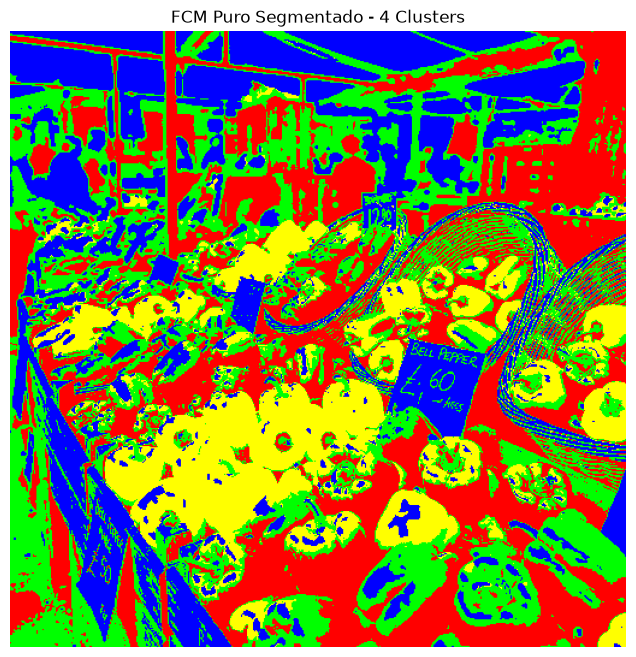

In [5]:
import time
import random
from PIL import Image
import matplotlib.pyplot as plt
import os

def fcm_processar_imagem(img, K, m=2.0, max_iter=100, epsilon=0.01):
    """
    Executa o pipeline completo do FCM Puro com proteções contra índice inválido e divisão por zero.
    """
    
    largura, altura = img.size
    
    # Extração segura dos pixels da imagem
    pixels_2d = list(img.getdata())
    
    # =======================c=============================================
    # ALVO: MISSÃO 3 (Structure of Arrays - SoA)
    # A equipe 3 deve DESTRUIR este for. Em vez de uma lista X com sublistas
    # [R, G, B], eles deverão criar três listas gigantes isoladas:
    # X_R = [], X_G = [], X_B = []
    # ====================================================================
    X = []
    for p in pixels_2d:
        X.append([float(p[0]), float(p[1]), float(p[2])])
        
    N = len(X)
    canais = 3
    
    paleta_cores = [
        [255, 0, 0],     # Cluster 0: Vermelho
        [0, 255, 0],     # Cluster 1: Verde
        [0, 0, 255],     # Cluster 2: Azul
        [255, 255, 0],   # Cluster 3: Amarelo
        [255, 0, 255],   # Cluster 4: Magenta
        [0, 255, 255]    # Cluster 5: Ciano
    ]
    
    # ====================================================================
    # ALVO: MISSÃO 1 (Memory Flattening)
    # A equipe 1 deve DESTRUIR a declaração bidimensional de U (lista de listas).
    # U deve ser um vetor achatado (1D) de tamanho N * K.
    # ====================================================================
    U = []
    for i in range(N):
        linha = []
        soma_linha = 0.0
        for j in range(K):
            val = random.random()
            linha.append(val)
            soma_linha += val
        
        for j in range(K):
            if soma_linha == 0.0:
                linha[j] = 1.0 / K
            else:
                linha[j] = linha[j] / soma_linha
        U.append(linha)
        
    # 4. LAÇO PRINCIPAL DO FCM (Puro)
    for iteracao in range(max_iter):
        
        # ====================================================================
        # ALVO: MISSÃO 2 (Fixed Point Math / Fuga da FPU)
        # A equipe 2 terá que modificar este laço e os laços subsequentes
        # para impedir o uso de float e a divisão decimal de numerador por 
        # denominador, usando shifiting (>>).
        # ====================================================================
        C = []
        for j in range(K):
            numerador = [0.0] * canais
            denominador = 0.0
            
            for i in range(N):
                u_m = U[i][j] ** m
                denominador += u_m
                
                # ====================================================================
                # ALVO: MISSÃO 4 (Loop Unrolling)
                # A equipe 4 deverá ELIMINAR este laço `for c in range(canais):` 
                # e desdobrar as operações manualmente (num_0 += ..., num_1 += ...)
                # ====================================================================
                for c in range(canais):
                    numerador[c] += u_m * X[i][c]
            
            centroide_j = []
            for c in range(canais):
                if denominador == 0.0:
                    centroide_j.append(0.0)
                else:
                    centroide_j.append(numerador[c] / denominador)
            C.append(centroide_j)
            
        U_nova = []
        max_diff = 0.0
        
        # ====================================================================
        # ALVO: MISSÃO 6 (Loop Fission)
        # A equipe 6 deverá DUPLICAR todo este bloco `for i in range(N):`.
        # Um laço roda a tela inteira APENAS calculando e salvando as distâncias 
        # em um array temporário gigante. Um segundo laço roda a tela de novo 
        # calculando a pertinência a partir desse array.
        # ====================================================================
        for i in range(N):
            linha_nova = [0.0] * K
            distancias = [0.0] * K
            
            for j in range(K):
                soma_quadrados = 0.0
                for c in range(canais):
                    diff = X[i][c] - C[j][c]
                    soma_quadrados += diff * diff
                distancias[j] = soma_quadrados ** 0.5 
                
                # ====================================================================
                # ALVO: MISSÃO 5 (Early Exit / Poda Condicional)
                # A equipe 5 deverá INJETAR aqui dentro um desvio:
                # Se 'distancias[j]' for maior que um limite arbitrário X, break.
                # ====================================================================
                
            for j in range(K):
                if distancias[j] == 0.0:
                    linha_nova[j] = 1.0
                    for k in range(K):
                        if k != j: 
                            linha_nova[k] = 0.0
                    break
                    
                soma_dist = 0.0
                for k in range(K):
                    d_k = distancias[k] if distancias[k] > 0.0 else 1e-10
                    razao = distancias[j] / d_k
                    soma_dist += razao ** (2.0 / (m - 1.0))
                
                pertinencia = 1.0 / soma_dist if soma_dist > 0.0 else (1.0 / K)
                linha_nova[j] = pertinencia
                
                diff_u = pertinencia - U[i][j]
                if diff_u < 0: 
                    diff_u = -diff_u
                if diff_u > max_diff: 
                    max_diff = diff_u
                
            U_nova.append(linha_nova)
            
        # O U TEM QUE SER ATUALIZADO AQUI FORA DO LAÇO DE PIXELS!
        U = U_nova
            
        if max_diff < epsilon:
            print(f"-> Convergiu na iteração {iteracao}!")
            break
            
    # 5. FASE 5: COLORIZAÇÃO POR PERTINÊNCIA MÁXIMA
    pixels_segmentados_lista = []
    for i in range(N):
        maior_pertinencia = -1.0
        cluster_vencedor = 0
        for j in range(K):
            if U[i][j] > maior_pertinencia:
                maior_pertinencia = U[i][j]
                cluster_vencedor = j
                
        cor = paleta_cores[cluster_vencedor % len(paleta_cores)]
        pixels_segmentados_lista.append((cor[0], cor[1], cor[2]))
        
    # 6. RESHAPE MANUAL E SALVAMENTO
    imagem_final = Image.new("RGB", (largura, altura))
    imagem_final.putdata(pixels_segmentados_lista)
    
    return C, U, imagem_final

# ==============================================================
# MAIN 
# ==============================================================
if __name__ == "__main__":
    # Defina o caminho da sua imagem real de teste e o nome da saída
    # imagem_entrada = "images/brain_256.jpeg"          
    
    K_clusters = 4                        
    fator_m = 2.0                         
    iteracoes_max = 100                    
    limite_epsilon = 0.001                
    
    print(f"--- INICIANDO PROCESSAMENTO DE BANCADA ---")
    print(f"Figura de Entrada: {imagem_entrada}")
    print(f"Clusters (K): {K_clusters}")

    # 1. LEITURA DA IMAGEM DO DISCO
    try:
        imagem = Image.open(imagem_entrada).convert("RGB")

        plt.figure(figsize=(8, 8))
        plt.title(f"Imagem Original")
        plt.imshow(imagem)
        plt.axis('off')
        plt.show()
        
        t0 = time.perf_counter()
        
        # ATENÇÃO: Agora pegando os 3 retornos corretamente
        centroides, pertinencias, imagem_segmentada = fcm_processar_imagem(
            img=imagem,
            K=K_clusters,
            m=fator_m,
            max_iter=iteracoes_max,
            epsilon=limite_epsilon
        )
        
        t1 = time.perf_counter()
        tempo_total = t1 - t0
        
        print(f"\n[SUCESSO] Processamento finalizado com folga!")
        print(f"Tempo Total de Execução (Bancada): {tempo_total:.4f} segundos")
        
        # Plotagem usando Matplotlib
        plt.figure(figsize=(8, 8))
        plt.title(f"FCM Puro Segmentado - {K_clusters} Clusters")
        plt.imshow(imagem_segmentada)
        plt.axis('off')
        plt.show()
        
    except FileNotFoundError:
        print(f"\n[ERRO] O arquivo '{imagem_entrada}' não foi encontrado.")
    except Exception as e:
        print(f"\n[ERRO INESPERADO] Ocorreu uma falha durante o processamento: {e}")
    

In [7]:
# Diretório com a lista de imagens para teste
pasta_imagens = "lista_imagens"


Mapeando imagens e calculando 'n' (apenas cabeçalhos)...
4 imagens ordenadas prontas para processamento.
Carregando natural_32.jpeg para a RAM (n=1024)...
-> Convergiu na iteração 7!
-> Convergiu na iteração 8!
-> Convergiu na iteração 12!
-> Convergiu na iteração 8!
-> Convergiu na iteração 7!
-> Convergiu na iteração 9!
-> Convergiu na iteração 8!
-> Convergiu na iteração 9!
-> Convergiu na iteração 8!
-> Convergiu na iteração 7!
-> Convergiu na iteração 8!
-> Convergiu na iteração 7!
-> Convergiu na iteração 9!
-> Convergiu na iteração 7!
-> Convergiu na iteração 8!
-> Convergiu na iteração 8!
-> Convergiu na iteração 10!
-> Convergiu na iteração 7!
-> Convergiu na iteração 11!
-> Convergiu na iteração 11!
-> Convergiu na iteração 8!
-> Convergiu na iteração 8!
-> Convergiu na iteração 8!
-> Convergiu na iteração 7!
-> Convergiu na iteração 7!
-> Convergiu na iteração 8!
-> Convergiu na iteração 15!
-> Convergiu na iteração 8!
-> Convergiu na iteração 8!
-> Convergiu na iteração 8!


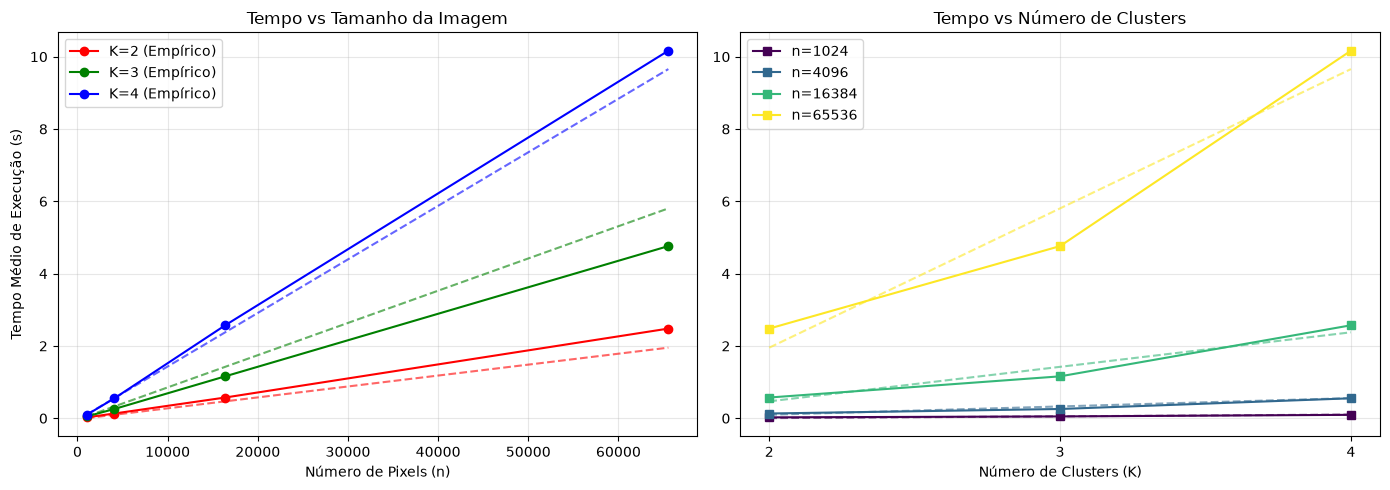

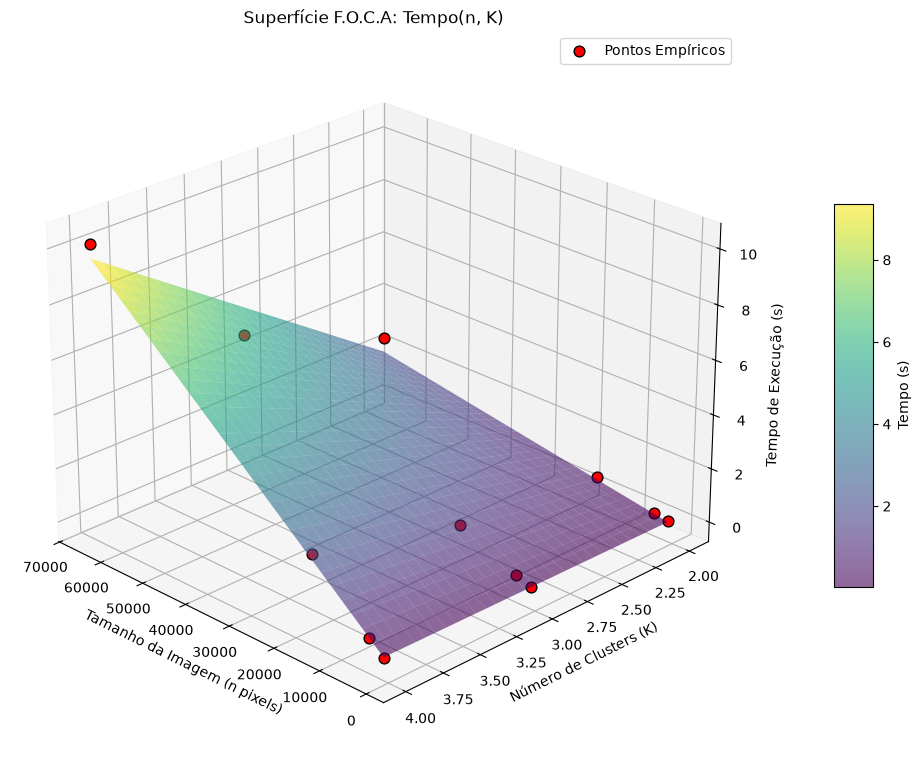


Pipeline concluído. Gráficos gerados e salvos como 'relatorio_complexidade.png'.
Tabela de avaliação exportada com sucesso para: outputs/resultados_foca_aluno.csv


In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.optimize import curve_fit

os.sched_setaffinity(0, {13})

# ==========================================
# 1. Função do Aluno (Mock)
# ==========================================
def segmenta_imagem(img, K, m=2.0, max_iter=100, epsilon=0.01):
    """
    Executa o pipeline completo do FCM Puro com proteções contra índice inválido e divisão por zero.
    """
    
    # largura, altura = img.size
    altura, largura = img.shape[:2]
    
    
    # Extração segura dos pixels da imagem
    # pixels_2d = list(img.getdata())
    # Achata a imagem 3D(altura, largura, 3) para uma lista 2D de pixels(N, 3)
    pixels_2d = img.reshape(-1, 3)
    
    # =======================c=============================================
    # ALVO: MISSÃO 3 (Structure of Arrays - SoA)
    # A equipe 3 deve DESTRUIR este for. Em vez de uma lista X com sublistas
    # [R, G, B], eles deverão criar três listas gigantes isoladas:
    # X_R = [], X_G = [], X_B = []
    # ====================================================================
    X = []
    for p in pixels_2d:
        X.append([float(p[0]), float(p[1]), float(p[2])])
        
    N = len(X)
    canais = 3
    
    paleta_cores = [
        [255, 0, 0],     # Cluster 0: Vermelho
        [0, 255, 0],     # Cluster 1: Verde
        [0, 0, 255],     # Cluster 2: Azul
        [255, 255, 0],   # Cluster 3: Amarelo
        [255, 0, 255],   # Cluster 4: Magenta
        [0, 255, 255]    # Cluster 5: Ciano
    ]
    
    # ====================================================================
    # ALVO: MISSÃO 1 (Memory Flattening)
    # A equipe 1 deve DESTRUIR a declaração bidimensional de U (lista de listas).
    # U deve ser um vetor achatado (1D) de tamanho N * K.
    # ====================================================================
    U = []
    for i in range(N):
        linha = []
        soma_linha = 0.0
        for j in range(K):
            val = random.random()
            linha.append(val)
            soma_linha += val
        
        for j in range(K):
            if soma_linha == 0.0:
                linha[j] = 1.0 / K
            else:
                linha[j] = linha[j] / soma_linha
        U.append(linha)
        
    # 4. LAÇO PRINCIPAL DO FCM (Puro)
    for iteracao in range(max_iter):
        
        # ====================================================================
        # ALVO: MISSÃO 2 (Fixed Point Math / Fuga da FPU)
        # A equipe 2 terá que modificar este laço e os laços subsequentes
        # para impedir o uso de float e a divisão decimal de numerador por 
        # denominador, usando shifiting (>>).
        # ====================================================================
        C = []
        for j in range(K):
            numerador = [0.0] * canais
            denominador = 0.0
            
            for i in range(N):
                u_m = U[i][j] ** m
                denominador += u_m
                
                # ====================================================================
                # ALVO: MISSÃO 4 (Loop Unrolling)
                # A equipe 4 deverá ELIMINAR este laço `for c in range(canais):` 
                # e desdobrar as operações manualmente (num_0 += ..., num_1 += ...)
                # ====================================================================
                for c in range(canais):
                    numerador[c] += u_m * X[i][c]
            
            centroide_j = []
            for c in range(canais):
                if denominador == 0.0:
                    centroide_j.append(0.0)
                else:
                    centroide_j.append(numerador[c] / denominador)
            C.append(centroide_j)
            
        U_nova = []
        max_diff = 0.0
        
        # ====================================================================
        # ALVO: MISSÃO 6 (Loop Fission)
        # A equipe 6 deverá DUPLICAR todo este bloco `for i in range(N):`.
        # Um laço roda a tela inteira APENAS calculando e salvando as distâncias 
        # em um array temporário gigante. Um segundo laço roda a tela de novo 
        # calculando a pertinência a partir desse array.
        # ====================================================================
        for i in range(N):
            linha_nova = [0.0] * K
            distancias = [0.0] * K
            
            for j in range(K):
                soma_quadrados = 0.0
                for c in range(canais):
                    diff = X[i][c] - C[j][c]
                    soma_quadrados += diff * diff
                distancias[j] = soma_quadrados ** 0.5 
                
                # ====================================================================
                # ALVO: MISSÃO 5 (Early Exit / Poda Condicional)
                # A equipe 5 deverá INJETAR aqui dentro um desvio:
                # Se 'distancias[j]' for maior que um limite arbitrário X, break.
                # ====================================================================
                
            for j in range(K):
                if distancias[j] == 0.0:
                    linha_nova[j] = 1.0
                    for k in range(K):
                        if k != j: 
                            linha_nova[k] = 0.0
                    break
                    
                soma_dist = 0.0
                for k in range(K):
                    d_k = distancias[k] if distancias[k] > 0.0 else 1e-10
                    razao = distancias[j] / d_k
                    soma_dist += razao ** (2.0 / (m - 1.0))
                
                pertinencia = 1.0 / soma_dist if soma_dist > 0.0 else (1.0 / K)
                linha_nova[j] = pertinencia
                
                diff_u = pertinencia - U[i][j]
                if diff_u < 0: 
                    diff_u = -diff_u
                if diff_u > max_diff: 
                    max_diff = diff_u
                
            U_nova.append(linha_nova)
            
        # O U TEM QUE SER ATUALIZADO AQUI FORA DO LAÇO DE PIXELS!
        U = U_nova
            
        if max_diff < epsilon:
            print(f"-> Convergiu na iteração {iteracao}!")
            break
            
    # 5. FASE 5: COLORIZAÇÃO POR PERTINÊNCIA MÁXIMA
    pixels_segmentados_lista = []
    for i in range(N):
        maior_pertinencia = -1.0
        cluster_vencedor = 0
        for j in range(K):
            if U[i][j] > maior_pertinencia:
                maior_pertinencia = U[i][j]
                cluster_vencedor = j
                
        cor = paleta_cores[cluster_vencedor % len(paleta_cores)]
        pixels_segmentados_lista.append((cor[0], cor[1], cor[2]))
        
    # 6. RESHAPE MANUAL E SALVAMENTO
    imagem_final = Image.new("RGB", (largura, altura))
    imagem_final.putdata(pixels_segmentados_lista)
    
    return C, U, imagem_final

# ==========================================
# 2. Descoberta e Ordenação Ligeira (Sem estourar RAM)
# ==========================================
img_dir = "lista_imagens" # Substitua pelo diretório real
k_list = [2, 3, 4]
R = 30 # Número de repetições por combinação

print("Mapeando imagens e calculando 'n' (apenas cabeçalhos)...")
arquivos_n = []

# Varre os arquivos no diretório especificado
if os.path.exists(img_dir):
    for filename in os.listdir(img_dir):
        if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
            filepath = os.path.join(img_dir, filename)
            
            # Image.open lê apenas os metadados. Não aloca a matriz de pixels.
            with Image.open(filepath) as img:
                w, h = img.size
                n = w * h
                arquivos_n.append({'arquivo': filename, 'caminho': filepath, 'n': n})

# Ordena a lista de dicionários pelo valor de 'n' crescente
arquivos_n = sorted(arquivos_n, key=lambda x: x['n'])

print(f"{len(arquivos_n)} imagens ordenadas prontas para processamento.")

# ==========================================
# 3. Execução (Carregando sob demanda)
# ==========================================
resultados = []

for item in arquivos_n:
    n = item['n']
    filepath = item['caminho']
    nome_arquivo = item['arquivo']
    
    print(f"Carregando {nome_arquivo} para a RAM (n={n})...")
    
    # Carrega a imagem real para a RAM apenas no momento de usar
    with Image.open(filepath) as img:
        img_array = np.array(img)
    
    # Executa todas as repetições e Ks para esta imagem
    for k in k_list:
        for r in range(R):
            t0 = time.perf_counter()
            segmenta_imagem(img_array, k)  # A matriz é passada aqui
            t1 = time.perf_counter()
            
            resultados.append({
                'arquivo': nome_arquivo,
                'n': n, 
                'k': k, 
                'repeticao': r, 
                'tempo': (t1 - t0)
            })
            
    # Libera a RAM explicitamente antes de carregar a próxima imagem
    del img_array
    print(f"Análise de {nome_arquivo} concluída. Memória liberada.")

# Transforma os resultados em DataFrame
df_raw = pd.DataFrame(resultados)

# ==========================================
# 4. Pré-processamento e Validação F.O.C.A.
# ==========================================
if not df_raw.empty:
    df_filtered = pd.DataFrame()
    
    # Filtragem de Outliers (Percentis 5 e 95)
    for (n, k), group in df_raw.groupby(['n', 'k']):
        p05 = group['tempo'].quantile(0.05)
        p95 = group['tempo'].quantile(0.95)
        valid_mask = (group['tempo'] >= p05) & (group['tempo'] <= p95)
        df_filtered = pd.concat([df_filtered, group[valid_mask]])
    
    # Validação de Estabilidade (Média, Desvio e CV)
    resumo = df_filtered.groupby(['n', 'k']).agg(
        tempo_medio=('tempo', 'mean'),
        desvio=('tempo', 'std'),
        contagem_valida=('tempo', 'count')
    ).reset_index()
    
    resumo['CV'] = resumo['desvio'] / resumo['tempo_medio']
    resumo['estavel_CV_menor_15'] = resumo['CV'] < 0.15
    
    print("\n--- Resumo de Estabilidade ---")
    print(resumo)
    
    # ==========================================
    # 5. Ajuste de Curvas
    # ==========================================
    def model_n_k(X, alpha, beta, gamma, delta):
        n, k = X
        return alpha * (n * k) + beta * n + gamma * k + delta
    
    X_data = np.vstack((resumo['n'], resumo['k']))
    y_data = resumo['tempo_medio']
    
    # O p0 pode precisar de sintonia dependendo da escala de tempo real
    popt, _ = curve_fit(model_n_k, X_data, y_data, p0=[1e-6, 1e-6, 1e-6, 0.01], maxfev=10000)
    resumo['tempo_predito'] = model_n_k(X_data, *popt)
    
    # ==========================================
    # 6. Plotagens Bidimensionais
    # ==========================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot A: Tempo vs n
    colors_k = ['red', 'green', 'blue', 'orange', 'purple'] 
    for idx, k in enumerate(k_list):
        dados_k = resumo[resumo['k'] == k]
        if not dados_k.empty:
            c = colors_k[idx % len(colors_k)]
            ax1.plot(dados_k['n'], dados_k['tempo_medio'], marker='o', 
                     color=c, label=f'K={k} (Empírico)')
            ax1.plot(dados_k['n'], dados_k['tempo_predito'], linestyle='--', 
                     color=c, alpha=0.6)
    
    ax1.set_xlabel('Número de Pixels (n)')
    ax1.set_ylabel('Tempo Médio de Execução (s)')
    ax1.set_title('Tempo vs Tamanho da Imagem')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot B: Tempo vs K
    n_processados = sorted(resumo['n'].unique())
    colors_n = plt.cm.viridis(np.linspace(0, 1, len(n_processados)))
    
    for idx, n_val in enumerate(n_processados):
        dados_n = resumo[resumo['n'] == n_val]
        if not dados_n.empty:
            ax2.plot(dados_n['k'], dados_n['tempo_medio'], marker='s', 
                     color=colors_n[idx], label=f'n={n_val}')
            ax2.plot(dados_n['k'], dados_n['tempo_predito'], linestyle='--', 
                     color=colors_n[idx], alpha=0.6)
    
    ax2.set_xlabel('Número de Clusters (K)')
    ax2.set_title('Tempo vs Número de Clusters')
    ax2.set_xticks(k_list)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('outputs/relatorio_complexidade.png', dpi=300)
    plt.show()
    
    # ==========================================
    # 6.5. Plotagem da Superfície 3D (Tempo vs n, k)
    # ==========================================
    fig_3d = plt.figure(figsize=(10, 8))
    ax_3d = fig_3d.add_subplot(111, projection='3d')
    
    # Cria uma malha contínua para a superfície teórica baseada nos limites reais
    n_linspace = np.linspace(resumo['n'].min(), resumo['n'].max(), 30)
    k_linspace = np.linspace(resumo['k'].min(), resumo['k'].max(), 30)
    N_mesh, K_mesh = np.meshgrid(n_linspace, k_linspace)
    
    # Aplica a equação ajustada (popt) em todos os pontos da malha
    T_mesh = model_n_k((N_mesh, K_mesh), *popt)
    
    # Desenha a superfície teórica (Translúcida)
    surf = ax_3d.plot_surface(N_mesh, K_mesh, T_mesh, cmap='viridis', alpha=0.6, 
                              linewidth=0.1, antialiased=True)
    fig_3d.colorbar(surf, ax=ax_3d, shrink=0.5, aspect=10, pad=0.1, label='Tempo (s)')
    
    # Sobrepõe os pontos empíricos medidos na bancada
    ax_3d.scatter(resumo['n'], resumo['k'], resumo['tempo_medio'], 
                  color='red', edgecolor='black', s=60, label='Pontos Empíricos', depthshade=False)
    
    # Configuração dos eixos e ângulos
    ax_3d.set_xlabel('Tamanho da Imagem (n pixels)')
    ax_3d.set_ylabel('Número de Clusters (K)')
    ax_3d.set_zlabel('Tempo de Execução (s)')
    ax_3d.set_title('Superfície F.O.C.A: Tempo(n, K)')
    ax_3d.view_init(elev=25, azim=135) # Ajuste o ângulo de visão conforme necessário
    ax_3d.legend()
    
    plt.tight_layout()
    plt.savefig('outputs/superficie_3d_foca.png', dpi=300)
    plt.show()
    
    print("\nPipeline concluído. Gráficos gerados e salvos como 'relatorio_complexidade.png'.")
	
	# ==========================================
    # 7. Exportação dos Dados para Avaliação
    # ==========================================
    arquivo_csv = 'outputs/resultados_foca_aluno.csv'
    
    # Exporta os dados usando ponto e vírgula como separador e vírgula para decimais,
    # garantindo que o arquivo seja aberto corretamente no Excel em PT-BR.
    resumo.to_csv(arquivo_csv, index=False, float_format='%.6f', sep=';', decimal=',')
    
    print(f"Tabela de avaliação exportada com sucesso para: {arquivo_csv}")
	
else:
    print("\nNenhum dado processado. Verifique se o diretório contém imagens válidas.")
	
	

Mapeando imagens e calculando 'n' (apenas cabeçalhos)...
4 imagens ordenadas prontas para processamento.
Carregando natural_96.jpeg para a RAM (n=9216)...
-> Convergiu na iteração 11!
-> Convergiu na iteração 9!
-> Convergiu na iteração 8!
-> Convergiu na iteração 9!
-> Convergiu na iteração 10!
-> Convergiu na iteração 10!
-> Convergiu na iteração 10!
-> Convergiu na iteração 9!
-> Convergiu na iteração 10!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 10!
-> Convergiu na iteração 8!
-> Convergiu na iteração 9!
-> Convergiu na iteração 11!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 8!
-> Convergiu na iteração 10!
-> Convergiu na iteração 9!
-> Convergiu na iteração 8!
-> Convergiu na iteração 10!
-> Convergiu na iteração 8!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração

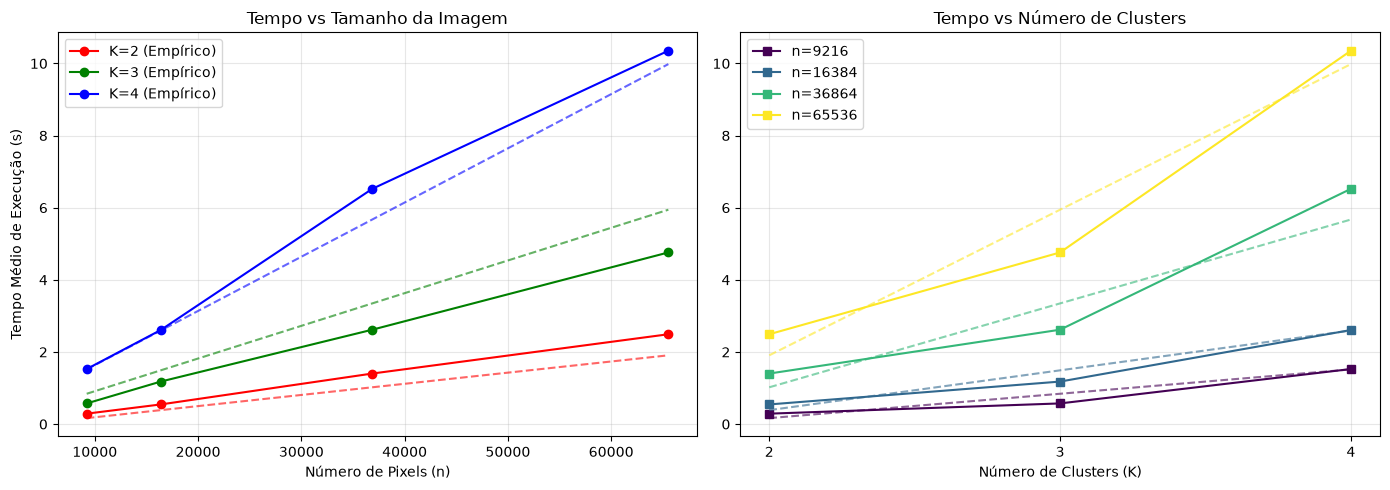

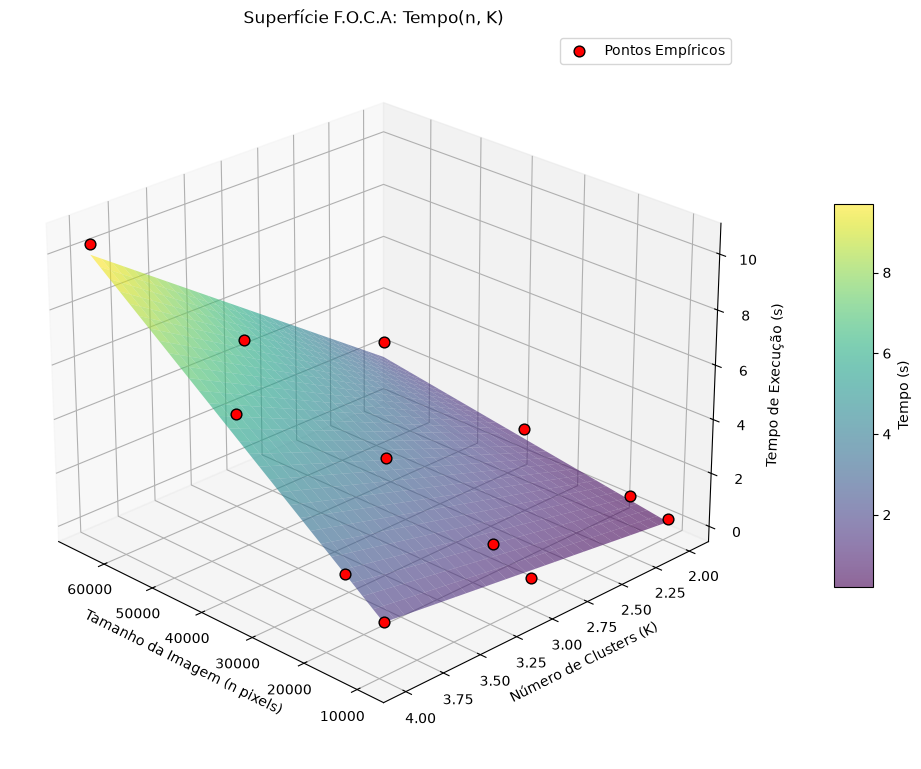


Pipeline concluído. Gráficos gerados e salvos como 'relatorio_complexidade.png'.
Tabela de avaliação exportada com sucesso para: outputs/resultados_foca_aluno2.csv


In [ ]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.optimize import curve_fit

os.sched_setaffinity(0, {13})

# ==========================================
# 1. Função do Aluno (Mock)
# ==========================================
def segmenta_imagem(img, K, m=2.0, max_iter=100, epsilon=0.01):
    """
    Executa o pipeline completo do FCM Puro com proteções contra índice inválido e divisão por zero.
    """
    
    # largura, altura = img.size
    altura, largura = img.shape[:2]
    
    
    # Extração segura dos pixels da imagem
    # pixels_2d = list(img.getdata())
    # Achata a imagem 3D(altura, largura, 3) para uma lista 2D de pixels(N, 3)
    pixels_2d = img.reshape(-1, 3)
    
    # =======================c=============================================
    # ALVO: MISSÃO 3 (Structure of Arrays - SoA)
    # A equipe 3 deve DESTRUIR este for. Em vez de uma lista X com sublistas
    # [R, G, B], eles deverão criar três listas gigantes isoladas:
    # X_R = [], X_G = [], X_B = []
    # ====================================================================
    X = []
    for p in pixels_2d:
        X.append([float(p[0]), float(p[1]), float(p[2])])
        
    N = len(X)
    canais = 3
    
    paleta_cores = [
        [255, 0, 0],     # Cluster 0: Vermelho
        [0, 255, 0],     # Cluster 1: Verde
        [0, 0, 255],     # Cluster 2: Azul
        [255, 255, 0],   # Cluster 3: Amarelo
        [255, 0, 255],   # Cluster 4: Magenta
        [0, 255, 255]    # Cluster 5: Ciano
    ]
    
    # ====================================================================
    # ALVO: MISSÃO 1 (Memory Flattening)
    # A equipe 1 deve DESTRUIR a declaração bidimensional de U (lista de listas).
    # U deve ser um vetor achatado (1D) de tamanho N * K.
    # ====================================================================
    U = []
    for i in range(N):
        linha = []
        soma_linha = 0.0
        for j in range(K):
            val = random.random()
            linha.append(val)
            soma_linha += val
        
        for j in range(K):
            if soma_linha == 0.0:
                linha[j] = 1.0 / K
            else:
                linha[j] = linha[j] / soma_linha
        U.append(linha)
        
    # 4. LAÇO PRINCIPAL DO FCM (Puro)
    for iteracao in range(max_iter):
        
        # ====================================================================
        # ALVO: MISSÃO 2 (Fixed Point Math / Fuga da FPU)
        # A equipe 2 terá que modificar este laço e os laços subsequentes
        # para impedir o uso de float e a divisão decimal de numerador por 
        # denominador, usando shifiting (>>).
        # ====================================================================
        C = []
        for j in range(K):
            numerador = [0.0] * canais
            denominador = 0.0
            
            for i in range(N):
                u_m = U[i][j] ** m
                denominador += u_m
                
                # ====================================================================
                # ALVO: MISSÃO 4 (Loop Unrolling)
                # A equipe 4 deverá ELIMINAR este laço `for c in range(canais):` 
                # e desdobrar as operações manualmente (num_0 += ..., num_1 += ...)
                # ====================================================================
                for c in range(canais):
                    numerador[c] += u_m * X[i][c]
            
            centroide_j = []
            for c in range(canais):
                if denominador == 0.0:
                    centroide_j.append(0.0)
                else:
                    centroide_j.append(numerador[c] / denominador)
            C.append(centroide_j)
            
        U_nova = []
        max_diff = 0.0
        
        # ====================================================================
        # ALVO: MISSÃO 6 (Loop Fission)
        # A equipe 6 deverá DUPLICAR todo este bloco `for i in range(N):`.
        # Um laço roda a tela inteira APENAS calculando e salvando as distâncias 
        # em um array temporário gigante. Um segundo laço roda a tela de novo 
        # calculando a pertinência a partir desse array.
        # ====================================================================
        for i in range(N):
            linha_nova = [0.0] * K
            distancias = [0.0] * K
            
            for j in range(K):
                soma_quadrados = 0.0
                for c in range(canais):
                    diff = X[i][c] - C[j][c]
                    soma_quadrados += diff * diff
                distancias[j] = soma_quadrados ** 0.5 
                
                # ====================================================================
                # ALVO: MISSÃO 5 (Early Exit / Poda Condicional)
                # A equipe 5 deverá INJETAR aqui dentro um desvio:
                # Se 'distancias[j]' for maior que um limite arbitrário X, break.
                # ====================================================================
                
            for j in range(K):
                if distancias[j] == 0.0:
                    linha_nova[j] = 1.0
                    for k in range(K):
                        if k != j: 
                            linha_nova[k] = 0.0
                    break
                    
                soma_dist = 0.0
                for k in range(K):
                    d_k = distancias[k] if distancias[k] > 0.0 else 1e-10
                    razao = distancias[j] / d_k
                    soma_dist += razao ** (2.0 / (m - 1.0))
                
                pertinencia = 1.0 / soma_dist if soma_dist > 0.0 else (1.0 / K)
                linha_nova[j] = pertinencia
                
                diff_u = pertinencia - U[i][j]
                if diff_u < 0: 
                    diff_u = -diff_u
                if diff_u > max_diff: 
                    max_diff = diff_u
                
            U_nova.append(linha_nova)
            
        # O U TEM QUE SER ATUALIZADO AQUI FORA DO LAÇO DE PIXELS!
        U = U_nova
            
        if max_diff < epsilon:
            print(f"-> Convergiu na iteração {iteracao}!")
            break
            
    # 5. FASE 5: COLORIZAÇÃO POR PERTINÊNCIA MÁXIMA
    pixels_segmentados_lista = []
    for i in range(N):
        maior_pertinencia = -1.0
        cluster_vencedor = 0
        for j in range(K):
            if U[i][j] > maior_pertinencia:
                maior_pertinencia = U[i][j]
                cluster_vencedor = j
                
        cor = paleta_cores[cluster_vencedor % len(paleta_cores)]
        pixels_segmentados_lista.append((cor[0], cor[1], cor[2]))
        
    # 6. RESHAPE MANUAL E SALVAMENTO
    imagem_final = Image.new("RGB", (largura, altura))
    imagem_final.putdata(pixels_segmentados_lista)
    
    return C, U, imagem_final

# ==========================================
# 2. Descoberta e Ordenação Ligeira (Sem estourar RAM)
# ==========================================
img_dir = "lista_imagens" # Substitua pelo diretório real
k_list = [2, 3, 4]
R = 30 # Número de repetições por combinação

print("Mapeando imagens e calculando 'n' (apenas cabeçalhos)...")
arquivos_n = []

# Varre os arquivos no diretório especificado
if os.path.exists(img_dir):
    for filename in os.listdir(img_dir):
        if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
            filepath = os.path.join(img_dir, filename)
            
            # Image.open lê apenas os metadados. Não aloca a matriz de pixels.
            with Image.open(filepath) as img:
                w, h = img.size
                n = w * h
                arquivos_n.append({'arquivo': filename, 'caminho': filepath, 'n': n})

# Ordena a lista de dicionários pelo valor de 'n' crescente
arquivos_n = sorted(arquivos_n, key=lambda x: x['n'])

print(f"{len(arquivos_n)} imagens ordenadas prontas para processamento.")

# ==========================================
# 3. Execução (Carregando sob demanda)
# ==========================================
resultados = []

for item in arquivos_n:
    n = item['n']
    filepath = item['caminho']
    nome_arquivo = item['arquivo']
    
    print(f"Carregando {nome_arquivo} para a RAM (n={n})...")
    
    # Carrega a imagem real para a RAM apenas no momento de usar
    with Image.open(filepath) as img:
        img_array = np.array(img)
    
    # Executa todas as repetições e Ks para esta imagem
    for k in k_list:
        for r in range(R):
            t0 = time.perf_counter()
            segmenta_imagem(img_array, k)  # A matriz é passada aqui
            t1 = time.perf_counter()
            
            resultados.append({
                'arquivo': nome_arquivo,
                'n': n, 
                'k': k, 
                'repeticao': r, 
                'tempo': (t1 - t0)
            })
            
    # Libera a RAM explicitamente antes de carregar a próxima imagem
    del img_array
    print(f"Análise de {nome_arquivo} concluída. Memória liberada.")

# Transforma os resultados em DataFrame
df_raw = pd.DataFrame(resultados)

# ==========================================
# 4. Pré-processamento e Validação F.O.C.A.
# ==========================================
if not df_raw.empty:
    df_filtered = pd.DataFrame()
    
    # Filtragem de Outliers (Percentis 5 e 95)
    for (n, k), group in df_raw.groupby(['n', 'k']):
        p05 = group['tempo'].quantile(0.05)
        p95 = group['tempo'].quantile(0.95)
        valid_mask = (group['tempo'] >= p05) & (group['tempo'] <= p95)
        df_filtered = pd.concat([df_filtered, group[valid_mask]])
    
    # Validação de Estabilidade (Média, Desvio e CV)
    resumo = df_filtered.groupby(['n', 'k']).agg(
        tempo_medio=('tempo', 'mean'),
        desvio=('tempo', 'std'),
        contagem_valida=('tempo', 'count')
    ).reset_index()
    
    resumo['CV'] = resumo['desvio'] / resumo['tempo_medio']
    resumo['estavel_CV_menor_15'] = resumo['CV'] < 0.15
    
    print("\n--- Resumo de Estabilidade ---")
    print(resumo)
    
    # ==========================================
    # 5. Ajuste de Curvas
    # ==========================================
    def model_n_k(X, alpha, beta, gamma, delta):
        n, k = X
        return alpha * (n * k) + beta * n + gamma * k + delta
    
    X_data = np.vstack((resumo['n'], resumo['k']))
    y_data = resumo['tempo_medio']
    
    # O p0 pode precisar de sintonia dependendo da escala de tempo real
    popt, _ = curve_fit(model_n_k, X_data, y_data, p0=[1e-6, 1e-6, 1e-6, 0.01], maxfev=10000)
    resumo['tempo_predito'] = model_n_k(X_data, *popt)
    
    # ==========================================
    # 6. Plotagens Bidimensionais
    # ==========================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot A: Tempo vs n
    colors_k = ['red', 'green', 'blue', 'orange', 'purple'] 
    for idx, k in enumerate(k_list):
        dados_k = resumo[resumo['k'] == k]
        if not dados_k.empty:
            c = colors_k[idx % len(colors_k)]
            ax1.plot(dados_k['n'], dados_k['tempo_medio'], marker='o', 
                     color=c, label=f'K={k} (Empírico)')
            ax1.plot(dados_k['n'], dados_k['tempo_predito'], linestyle='--', 
                     color=c, alpha=0.6)
    
    ax1.set_xlabel('Número de Pixels (n)')
    ax1.set_ylabel('Tempo Médio de Execução (s)')
    ax1.set_title('Tempo vs Tamanho da Imagem')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot B: Tempo vs K
    n_processados = sorted(resumo['n'].unique())
    colors_n = plt.cm.viridis(np.linspace(0, 1, len(n_processados)))
    
    for idx, n_val in enumerate(n_processados):
        dados_n = resumo[resumo['n'] == n_val]
        if not dados_n.empty:
            ax2.plot(dados_n['k'], dados_n['tempo_medio'], marker='s', 
                     color=colors_n[idx], label=f'n={n_val}')
            ax2.plot(dados_n['k'], dados_n['tempo_predito'], linestyle='--', 
                     color=colors_n[idx], alpha=0.6)
    
    ax2.set_xlabel('Número de Clusters (K)')
    ax2.set_title('Tempo vs Número de Clusters')
    ax2.set_xticks(k_list)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('outputs/relatorio_complexidade.png', dpi=300)
    plt.show()
    
    # ==========================================
    # 6.5. Plotagem da Superfície 3D (Tempo vs n, k)
    # ==========================================
    fig_3d = plt.figure(figsize=(10, 8))
    ax_3d = fig_3d.add_subplot(111, projection='3d')
    
    # Cria uma malha contínua para a superfície teórica baseada nos limites reais
    n_linspace = np.linspace(resumo['n'].min(), resumo['n'].max(), 30)
    k_linspace = np.linspace(resumo['k'].min(), resumo['k'].max(), 30)
    N_mesh, K_mesh = np.meshgrid(n_linspace, k_linspace)
    
    # Aplica a equação ajustada (popt) em todos os pontos da malha
    T_mesh = model_n_k((N_mesh, K_mesh), *popt)
    
    # Desenha a superfície teórica (Translúcida)
    surf = ax_3d.plot_surface(N_mesh, K_mesh, T_mesh, cmap='viridis', alpha=0.6, 
                              linewidth=0.1, antialiased=True)
    fig_3d.colorbar(surf, ax=ax_3d, shrink=0.5, aspect=10, pad=0.1, label='Tempo (s)')
    
    # Sobrepõe os pontos empíricos medidos na bancada
    ax_3d.scatter(resumo['n'], resumo['k'], resumo['tempo_medio'], 
                  color='red', edgecolor='black', s=60, label='Pontos Empíricos', depthshade=False)
    
    # Configuração dos eixos e ângulos
    ax_3d.set_xlabel('Tamanho da Imagem (n pixels)')
    ax_3d.set_ylabel('Número de Clusters (K)')
    ax_3d.set_zlabel('Tempo de Execução (s)')
    ax_3d.set_title('Superfície F.O.C.A: Tempo(n, K)')
    ax_3d.view_init(elev=25, azim=135) # Ajuste o ângulo de visão conforme necessário
    ax_3d.legend()
    
    plt.tight_layout()
    plt.savefig('outputs/superficie_3d_foca.png', dpi=300)
    plt.show()
    
    print("\nPipeline concluído. Gráficos gerados e salvos como 'relatorio_complexidade.png'.")
	
	# ==========================================
    # 7. Exportação dos Dados para Avaliação
    # ==========================================
    arquivo_csv = 'outputs/resultados_foca_aluno.csv'
    
    # Exporta os dados usando ponto e vírgula como separador e vírgula para decimais,
    # garantindo que o arquivo seja aberto corretamente no Excel em PT-BR.
    resumo.to_csv(arquivo_csv, index=False, float_format='%.6f', sep=';', decimal=',')
    
    print(f"Tabela de avaliação exportada com sucesso para: {arquivo_csv}")
	
else:
    print("\nNenhum dado processado. Verifique se o diretório contém imagens válidas.")
	
	